## This notebook demonstrates access to NOAA Coastal Ocean ReAnalysis (CORA) data that is stored in an S3 bucket and made freely available via NOAA's Open Data Dissemination (NODD) service. The data will be loaded as an xarray dataset. For a use case example, wave data is extracted at the nearest model node to user provided geographic coordinates and the data is displayed in a time series plot. 

Access all the data in the S3 bucket here: https://noaa-nos-cora-pds.s3.amazonaws.com/index.html

*Parts of the code in this notebook were guided by **Signell, R. (2024). Reproducible Notebooks/hurricane-ike-water-levels. https://github.com/reproducible-notebooks/hurricane-ike-water-levels/tree/master***

_ _

### Input a location of interest in the format (lat, lon) ###

In [1]:
#loc = (44.61, -124.08)  # Near the Yaquina Bay north jetty, Oregon
loc = (47.809930, -122.793780)  # Dabob Bay alternatives to hard armoring example

### Import packages ###

In [2]:
import intake
import numpy as np
import zarr

### Initialize and list the available CORA datasets ###
Description of datasets: <br>
**CORA-{domain}-fort.63-{chunking}**: Hourly water levels <br>
**CORA-{domain}-swan_TPS.63-{chunking}**: Hourly spectral peak wave periods <br>
**CORA-{domain}-swan_DIR.63-{chunking}**: Hourly mean wave directions <br>
**CORA-{domain}-swan_HS.63-{chunking}**: Hourly significant wave heights <br>
**CORA-{domain}-Grid-{chunking}**: Hourly water levels interpolated from model nodes to a uniform 500 meter resolution grid <br>

Where: <br>
**{domain}** represents the domain. Options are **GEC** or **PAC**. <br>
**{chunking}** represents the chunking strategy, which affects data loading speed. Use **timeseries** if you are interested in long timeseries at a few points, use **map** if you are interested in many points for a few time periods (up to a few days).

In [3]:
if int(zarr.__version__[0]) > 2:  ## There are some issues with zarr 2 vs. zarr 3, so two catalogs have been created depdning on the zarr version you are using.
    catalog_file = 'CORA_intake_zarr3.yml'
else:
    catalog_file = 'CORA_intake.yml'

catalog = intake.open_catalog("s3://noaa-nos-cora-pds/"+catalog_file,storage_options={'anon':True})
list(catalog)

['CORA-GEC-fort.63-map',
 'CORA-GEC-fort.63-timeseries',
 'CORA-GEC-swan_TPS.63-map',
 'CORA-GEC-swan_TPS.63-timeseries',
 'CORA-GEC-swan_DIR.63-map',
 'CORA-GEC-swan_DIR.63-timeseries',
 'CORA-GEC-swan_HS.63-map',
 'CORA-GEC-swan_HS.63-timeseries',
 'CORA-GEC-Grid',
 'CORA-GEC-Grid-timeseries',
 'CORA-PAC-fort.63-map',
 'CORA-PAC-fort.63-timeseries',
 'CORA-PAC-swan_TPS.63-map',
 'CORA-PAC-swan_TPS.63-timeseries',
 'CORA-PAC-swan_DIR.63-map',
 'CORA-PAC-swan_DIR.63-timeseries',
 'CORA-PAC-swan_HS.63-map',
 'CORA-PAC-swan_HS.63-timeseries']

### Initialize CORA-PAC waves (see full dataset [here](https://noaa-nos-cora-pds.s3.amazonaws.com/index.html#cora_pac/native_grid/waves/)). ###
#### This dataset contains hourly wave data from 1979-2025 in the PAC domain. The dataset is multiple TB in size and cannot be loaded into memory on a standard computer. We use the xarray package to "lazily" load the data - initializing it and only loading the pieces that we need later. Note that we use the **timeseries** chunking here, since we are interested in a timseries at a single point.

In [4]:
ds = catalog["CORA-PAC-swan_HS.63-timeseries"].to_dask()  # We will use Hs here, could also use Tp or Dir
ds

<xarray.Dataset> Size: 3TB
Dimensions:      (node: 1991641, nfaces: 3719525, nvertex: 3, nbou: 2522,
                  nope: 1, neta: 825, nvel: 270489, time: 412008)
Coordinates:
    x            (node) float64 16MB dask.array<chunksize=(1991641,), meta=np.ndarray>
    y            (node) float64 16MB dask.array<chunksize=(1991641,), meta=np.ndarray>
  * time         (time) datetime64[ns] 3MB 1979-01-01 ... 2025-12-31T23:00:00
Dimensions without coordinates: node, nfaces, nvertex, nbou, nope, neta, nvel
Data variables:
    adcirc_mesh  float64 8B ...
    depth        (node) float64 16MB dask.array<chunksize=(1991641,), meta=np.ndarray>
    element      (nfaces, nvertex) float64 89MB dask.array<chunksize=(3719525, 3), meta=np.ndarray>
    ibtype       (nbou) float64 20kB dask.array<chunksize=(2522,), meta=np.ndarray>
    ibtypee      (nope) float64 8B dask.array<chunksize=(1,), meta=np.ndarray>
    nbdv         (neta) float64 7kB dask.array<chunksize=(825,), meta=np.ndarray>
    nbvv         (nvel) float64 2MB dask.array<chunksize=(270489,), meta=np.ndarray>
    nvdll        (nope) float64 8B dask.array<chunksize=(1,), meta=np.ndarray>
    nvell        (nbou) float64 20kB dask.array<chunksize=(2522,), meta=np.ndarray>
    swan_HS      (time, node) float32 3TB dask.array<chunksize=(35064, 200), meta=np.ndarray>
Attributes: (12/47)
    Conventions:  UGRID-0.9.0
    a00:          0.8
    agrid:        enp_tga_neglong_v0.1
    b00:          0.2
    c00:          0.0
    cf:           0.0005
    ...           ...
    slam0:        -145.0
    source:       NOAA Gaea C6
    statim:       0.0
    tau0:         0.0533333
    title:        NOAA-ENP-Reanalysis-Post
    version:      v56.2.0-beta.1-7-g35fbf359

### Find the closest node to the location of interest (using the haversine formula), load the timeseries for the year 1979, and plot it. ###
#### The time slice of interest can be modified. The longer the time slice, the longer it will take to load the selected data into memory. ####

<class 'int'>
-122.795
47.809488


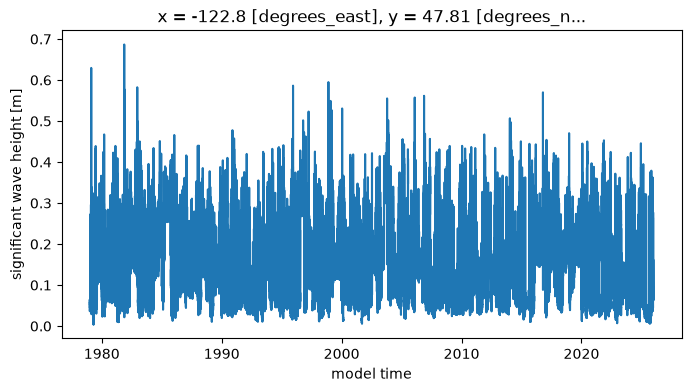

In [5]:
def haversine(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.radians, [lat1, lon1, lat2, lon2])
    R = 6371 
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = np.sin(dlat/2.0)**2 + np.cos(lat1) * np.cos(lat2) * np.sin(dlon/2.0)**2
    c = 2 * np.arcsin(np.sqrt(a))
    km = R * c
    return km 

d = haversine(loc[0],loc[1],ds.y,ds.x)
closest_node = int(np.argmin(d.data))

print(type(closest_node))   # ERE investigating 
print(ds.x.sel(node=closest_node).values)
print(ds.y.sel(node=closest_node).values)



#ts = ds['swan_HS'].sel(node=closest_node,time=slice("1979-1-1","1979-12-31"))
#ts.plot(figsize=(8,4))

ts = ds['swan_HS'].sel(node=closest_node,time=slice("1979-1-1","2025-12-31"))   # ERE experimenting w different timeslice
ts.plot(figsize=(8,4))

### Calculating Summary Statistics for Wave Height & Plotting a histogram ###

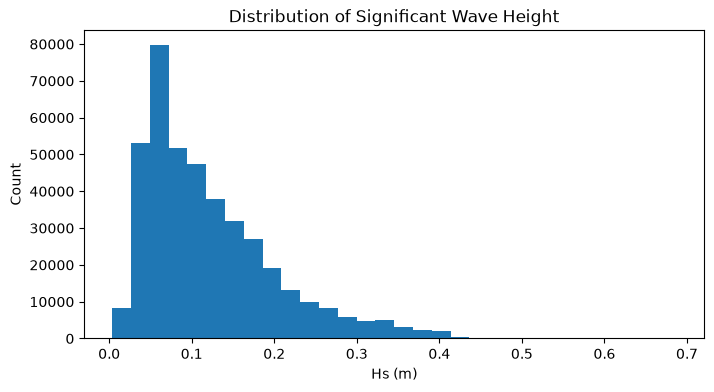

Mean Hs (2025): 0.12 m
95th percentile Hs: 0.29 m


In [6]:
import matplotlib.pyplot as plt

ts_series = ts.compute()

plt.figure(figsize=(8,4))
plt.hist(ts_series, bins=30)
plt.xlabel("Hs (m)")
plt.ylabel("Count")
plt.title("Distribution of Significant Wave Height")
plt.show()

# Computing summary statistics for waves 
mean_hs = float(ts.mean().compute())   # ERE
print(f"Mean Hs (2025): {mean_hs:.2f} m")   # ERE

p95 = float(ts.quantile(0.95).compute())
print(f"95th percentile Hs: {p95:.2f} m")